# Drift-Aware Machine Learning for Stock Market Prediction — 1-Day (Next-Session) Predictor

**Research question:** *Does adapting machine learning models to recent market conditions improve market-direction prediction for SPY compared with keeping the models fixed?*

This notebook is the **1-day (next-session)** version of the project. A companion notebook (`spy_drift_5day.ipynb`) runs the identical pipeline for the 5-session (1-week) horizon.

| Item | Choice |
|---|---|
| Target asset | SPDR S&P 500 ETF (SPY) |
| Label | 1 if SPY's next-session **close > open**, else 0 |
| Decision time | After the close of session *t* (features use only data available at that close) |
| Predictors | SPY price/volume features, related ETFs (QQQ, IWM, 9 sector SPDRs, TLT, IEF, GLD) and ^VIX |
| Models | Majority-class baseline, regularized logistic regression, histogram gradient-boosted trees |
| Adaptation schemes | **Fixed** (train once) vs **Expanding-window** retraining vs **Rolling-window** retraining |
| Splits | Train 2008–2016 · Validation 2017–2018 · Test 2019–2025 (chronological) |
| Metrics | Balanced accuracy (primary), ROC-AUC, Brier score |

**Pipeline outline**

1. Setup & configuration
2. Data collection (`yfinance`, cached locally)
3. Data quality audit & trading-calendar alignment
4. Target construction
5. Feature engineering (+ automated look-ahead leakage test)
6. Exploratory analysis & drift diagnostics
7. Chronological splits with purging
8. Hyperparameter tuning on the validation period
9. Selection of retraining frequency / window on the validation period
10. Walk-forward evaluation on the test period (main experiment)
11. Statistical comparison (block bootstrap)
12. Performance over time, by volatility regime, and by year
13. Cross-market feature ablation
14. Model interpretation (coefficients over time, permutation importance) & calibration
15. Exploratory trading simulation with transaction costs
16. Summary of findings

## 1. Setup & configuration

In [1]:
import os, warnings, time
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GroupKFold, cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, brier_score_loss,
                             accuracy_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["figure.dpi"] = 100

In [2]:
# ---------------- Experiment configuration ----------------
HORIZON = 1          # prediction horizon in trading sessions (1 = next day)
SEED = 42
np.random.seed(SEED)

DOWNLOAD_START = "2006-01-01"        # extra history = warm-up for 200/252-day features
STUDY_START, STUDY_END = "2008-01-01", "2025-12-31"
TRAIN_END, VAL_END = "2016-12-31", "2018-12-31"   # test = 2019-01-01 .. STUDY_END

TARGET = "SPY"
EQUITY = ["SPY", "QQQ", "IWM"]
SECTORS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]  # XLRE/XLC excluded: start 2015/2018
BONDS = ["TLT", "IEF"]
COMMODITIES = ["GLD"]
VOLATILITY = ["^VIX"]
ALL_TICKERS = EQUITY + SECTORS + BONDS + COMMODITIES + VOLATILITY

DATA_DIR = Path("data")
RESULTS_DIR = Path("results") / f"h{HORIZON}"
for d in (DATA_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
RAW_CACHE = DATA_DIR / "raw_prices.pkl"
FORCE_DOWNLOAD = False               # set True to refresh the cached Yahoo data

# Adaptation-scheme search space (selected on validation data)
RETRAIN_EVERY_GRID = [21, 63]                    # ~monthly, ~quarterly (trading days)
ROLLING_WINDOW_GRID = [252, 504, 1008, 1512]     # ~1, 2, 4, 6 years
SELECTION_METRIC = "roc_auc"                     # threshold-free and less noisy than balanced accuracy

# Statistics / simulation
N_BOOT = 1000
BLOCK_LEN = max(20, 3 * HORIZON)                 # moving-block bootstrap block length
COST_GRID_BPS = [0, 2, 5, 10, 20]                # round-trip transaction cost per trade

def savefig(name):
    plt.savefig(RESULTS_DIR / f"{name}.png", bbox_inches="tight")

print(f"Horizon: {HORIZON} session(s) | results -> {RESULTS_DIR.resolve()}")

Horizon: 1 session(s) | results -> C:\UT\381K\Final Project\results\h1


## 2. Data collection

Daily OHLCV data are downloaded from Yahoo Finance with `yfinance` and cached to `data/raw_prices.pkl`, so later runs (and the companion notebook) are fast and reproducible.

* `auto_adjust=True` rescales Open/High/Low/Close by the same split/dividend factor. Ratios measured within a day (e.g., close ÷ open) are unchanged, and multi-day returns include dividends.
* ^VIX is an index, so it has no meaningful volume. Only its price fields are used.

In [3]:
def download_prices(tickers, start, end, cache, force=False):
    if cache.exists() and not force:
        raw = pd.read_pickle(cache)
        if set(tickers) <= set(raw.columns.get_level_values("ticker")):
            print(f"Loaded cached prices from {cache} ({raw.shape[0]:,} rows)")
            return raw
    end_exclusive = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    raw = yf.download(tickers, start=start, end=end_exclusive, auto_adjust=True,
                      progress=False, group_by="column", threads=True)
    raw.columns.names = ["field", "ticker"]
    raw.to_pickle(cache)
    print(f"Downloaded {len(tickers)} tickers -> {cache} ({raw.shape[0]:,} rows)")
    return raw

raw = download_prices(ALL_TICKERS, DOWNLOAD_START, STUDY_END, RAW_CACHE, FORCE_DOWNLOAD)
raw.columns.names = ["field", "ticker"]
FIELDS = ["Open", "High", "Low", "Close", "Volume"]
px_raw = {t: raw.xs(t, axis=1, level="ticker")[FIELDS].copy() for t in ALL_TICKERS}
px_raw["SPY"].tail()

Loaded cached prices from data\raw_prices.pkl (5,031 rows)


field,Open,High,Low,Close,Volume
Date,,,,,
2025-12-24,682.6183,685.4760,682.4695,685.0295,39445600
2025-12-26,685.2875,686.2995,683.9281,684.9600,41613300
2025-12-29,682.2114,683.8586,680.7529,682.5190,62559500
2025-12-30,682.1221,683.2235,681.2589,681.6855,47160700
2025-12-31,681.8146,682.0329,676.4267,676.6350,74144800


## 3. Data quality audit & calendar alignment

SPY's trading days are the master calendar. For each instrument we document:

* first/last available date and number of observations,
* SPY trading days on which the instrument has no data (**missing**),
* days the instrument has data but SPY does not (**extra**, dropped),
* non-positive prices, OHLC inconsistencies (High < max(Open, Close) or Low > min(Open, Close)), and zero-volume days.

Missing values are forward-filled for **at most 3 sessions**. This uses only past data, so it cannot leak future information. Any remaining gaps are left as NaN and removed later.

In [4]:
calendar = px_raw["SPY"].dropna(subset=["Close"]).index
tol = 1e-6
rows = []
for t, d in px_raw.items():
    valid = d.dropna(subset=["Close"])
    on_cal = d.reindex(calendar)
    after_first = on_cal.loc[valid.index.min():]
    ohlc_bad = ((valid["High"] < valid[["Open", "Close"]].max(axis=1) * (1 - tol)) |
                (valid["Low"] > valid[["Open", "Close"]].min(axis=1) * (1 + tol))).sum()
    rows.append({
        "ticker": t,
        "first_date": valid.index.min().date(),
        "last_date": valid.index.max().date(),
        "n_obs": len(valid),
        "missing_on_spy_days": int(after_first["Close"].isna().sum()),
        "extra_days_dropped": int((~valid.index.isin(calendar)).sum()),
        "nonpositive_prices": int((valid[["Open", "High", "Low", "Close"]] <= 0).sum().sum()),
        "ohlc_inconsistent": int(ohlc_bad),
        "zero_volume_days": np.nan if t == "^VIX" else int((valid["Volume"] == 0).sum()),
    })
quality = pd.DataFrame(rows).set_index("ticker")
quality.to_csv(RESULTS_DIR / "data_quality.csv")
quality

,first_date,last_date,n_obs,missing_on_spy_days,extra_days_dropped,nonpositive_prices,ohlc_inconsistent,zero_volume_days
ticker,,,,,,,,
SPY,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
QQQ,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
IWM,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
XLB,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
XLE,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
XLF,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
XLI,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
XLK,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000
XLP,2006-01-03,2025-12-31,5031,0,0,0,0,0.0000


In [5]:
FFILL_LIMIT = 3
px, fill_counts = {}, {}
for t, d in px_raw.items():
    d = d.reindex(calendar)
    before = d["Close"].isna().sum()
    d = d.ffill(limit=FFILL_LIMIT)
    fill_counts[t] = int(before - d["Close"].isna().sum())
    if t == "^VIX":
        d["Volume"] = np.nan   # not meaningful for an index
    px[t] = d

dup = calendar.duplicated().sum()
print(f"Master calendar: {calendar.min().date()} -> {calendar.max().date()}, {len(calendar):,} sessions, duplicates={dup}")
print("Forward-filled cells per ticker (Close):", {k: v for k, v in fill_counts.items() if v})
pd.to_pickle(px, DATA_DIR / "aligned_prices.pkl")

Master calendar: 2006-01-03 -> 2025-12-31, 5,031 sessions, duplicates=0
Forward-filled cells per ticker (Close): {}


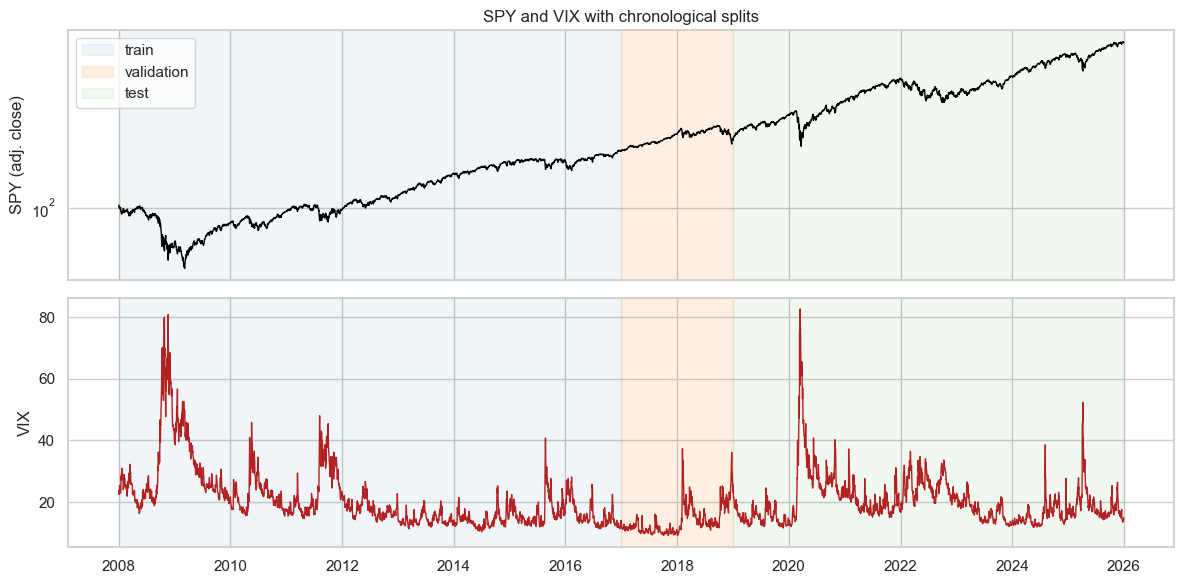

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
s = px["SPY"]["Close"].loc[STUDY_START:STUDY_END]
v = px["^VIX"]["Close"].loc[STUDY_START:STUDY_END]
ax[0].plot(s, color="black", lw=1); ax[0].set_ylabel("SPY (adj. close)"); ax[0].set_yscale("log")
ax[1].plot(v, color="firebrick", lw=1); ax[1].set_ylabel("VIX")
for a in ax:
    a.axvspan(pd.Timestamp(STUDY_START), pd.Timestamp(TRAIN_END), color="tab:blue", alpha=0.07, label="train")
    a.axvspan(pd.Timestamp(TRAIN_END), pd.Timestamp(VAL_END), color="tab:orange", alpha=0.12, label="validation")
    a.axvspan(pd.Timestamp(VAL_END), pd.Timestamp(STUDY_END), color="tab:green", alpha=0.07, label="test")
ax[0].legend(loc="upper left"); ax[0].set_title("SPY and VIX with chronological splits")
plt.tight_layout(); savefig("spy_vix_splits"); plt.show()

## 4. Target construction

For each session *t*:

$$y_t = \mathbb{1}\left[\text{Close}_{t+1} > \text{Open}_{t+1}\right]$$

The prediction is made after the close of *t* for the **intraday** move of the next session. The overnight gap (Close_t → Open_{t+1}) is excluded, so the target describes a position opened at the next open and closed at the next close.

The label for row *t* becomes known at the close of session *t + 1*. That date is stored as `label_end`. Every training step uses only rows whose `label_end` is on or before the decision date (**purging**). This prevents labels that overlap the evaluation period from entering training.

In [7]:
spy = px["SPY"]
entry = spy["Open"].shift(-1)                # next session's open
exit_ = spy["Close"].shift(-HORIZON)         # close HORIZON sessions ahead
fwd_ret = exit_ / entry - 1
target = (fwd_ret > 0).astype(float).where(fwd_ret.notna())
label_end = pd.Series(calendar, index=calendar).shift(-HORIZON)

print(f"Positive rate (study period): {target.loc[STUDY_START:STUDY_END].mean():.3f}")
print(f"Rows without a label (end of sample): {int(target.isna().sum())}")

Positive rate (study period): 0.540
Rows without a label (end of sample): 1


## 5. Feature engineering

Every feature for session *t* is computed from data available **at or before the close of *t***: backward-looking rolling windows, `diff`/`shift` with positive lags, and no centered windows.

**SPY-only features (`spy_*`, `cal_*`)**
* Log returns over 1, 2, 3, 5, 10, 20, 60, 120, 250 sessions; lagged 1-day returns; overnight-gap and intraday returns
* Realized volatility (5/10/20/60d), volatility ratio, Parkinson high–low volatility, ATR, daily range and its z-score
* Price vs. 10/20/50/200-day SMAs, 50/200 SMA cross, Bollinger z-score, RSI(14), distance from 52-week high/low, close location within the day's range, 60-day skewness, fraction of up days
* Volume z-score, 5/60 volume ratio, 1-day volume change
* Calendar: day-of-week dummies, month (sine/cosine)

**Cross-market features**
* 1/5/20-day returns and 50-day SMA distance for QQQ, IWM, 9 sector ETFs, TLT, IEF, GLD
* Relative performance: QQQ−SPY, IWM−SPY (size/growth), TLT−IEF (duration/curve proxy), GLD−SPY, XLY−XLP (risk appetite)
* Sector dispersion and breadth (share of sectors up today / above their 50-day SMA)
* VIX level, changes, z-score, 1-year percentile rank, VIX minus realized volatility (variance-risk-premium proxy), VIX intraday range
* 60-day SPY–TLT return correlation (stock–bond regime)

In [8]:
def log_ret(s, k=1):
    return np.log(s).diff(k)

def zscore(s, w):
    return (s - s.rolling(w).mean()) / s.rolling(w).std()

def rsi(close, n=14):
    d = close.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn)

def spy_features(d):
    c, o, h, l, v = d["Close"], d["Open"], d["High"], d["Low"], d["Volume"]
    r = log_ret(c)
    f = {}
    for k in [1, 2, 3, 5, 10, 20, 60, 120, 250]:
        f[f"spy_ret_{k}d"] = log_ret(c, k)
    f["spy_ret_1d_lag1"] = r.shift(1)
    f["spy_ret_1d_lag2"] = r.shift(2)
    f["spy_intraday_ret"] = np.log(c / o)
    f["spy_overnight_ret"] = np.log(o / c.shift(1))
    for w in [5, 10, 20, 60]:
        f[f"spy_vol_{w}d"] = r.rolling(w).std() * np.sqrt(252)
    f["spy_vol_ratio_5_60"] = f["spy_vol_5d"] / f["spy_vol_60d"]
    f["spy_parkinson_vol_20d"] = np.sqrt((np.log(h / l) ** 2).rolling(20).mean() / (4 * np.log(2)) * 252)
    f["spy_range_pct"] = (h - l) / c
    f["spy_range_z20"] = zscore(f["spy_range_pct"], 20)
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    f["spy_atr14_pct"] = tr.rolling(14).mean() / c
    f["spy_close_location"] = ((c - l) / (h - l)).where(h > l, 0.5)
    for w in [10, 20, 50, 200]:
        f[f"spy_px_vs_sma{w}"] = c / c.rolling(w).mean() - 1
    f["spy_sma50_vs_sma200"] = c.rolling(50).mean() / c.rolling(200).mean() - 1
    f["spy_bollinger_z20"] = zscore(c, 20)
    f["spy_rsi14"] = rsi(c)
    f["spy_dist_252d_high"] = c / c.rolling(252).max() - 1
    f["spy_dist_252d_low"] = c / c.rolling(252).min() - 1
    f["spy_skew_60d"] = r.rolling(60).skew()
    f["spy_up_frac_10d"] = (r > 0).astype(float).rolling(10).mean()
    lv = np.log(v.replace(0, np.nan))
    f["spy_volume_z20"] = zscore(lv, 20)
    f["spy_volume_ratio_5_60"] = v.rolling(5).mean() / v.rolling(60).mean()
    f["spy_volume_chg_1d"] = lv.diff()
    return pd.DataFrame(f)

def calendar_features(idx):
    f = pd.DataFrame(index=idx)
    for k in range(5):
        f[f"cal_dow_{k}"] = (idx.dayofweek == k).astype(float)
    f["cal_month_sin"] = np.sin(2 * np.pi * idx.month / 12)
    f["cal_month_cos"] = np.cos(2 * np.pi * idx.month / 12)
    return f

def cross_features(px):
    f = {}
    spy_c = px["SPY"]["Close"]
    for t in EQUITY[1:] + SECTORS + BONDS + COMMODITIES:
        c, n = px[t]["Close"], t.lower()
        for k in [1, 5, 20]:
            f[f"{n}_ret_{k}d"] = log_ret(c, k)
        f[f"{n}_px_vs_sma50"] = c / c.rolling(50).mean() - 1
    rel = lambda a, b, k: log_ret(px[a]["Close"], k) - log_ret(px[b]["Close"], k)
    for k in [5, 20]:
        f[f"qqq_minus_spy_ret_{k}d"] = rel("QQQ", "SPY", k)
        f[f"iwm_minus_spy_ret_{k}d"] = rel("IWM", "SPY", k)
        f[f"tlt_minus_ief_ret_{k}d"] = rel("TLT", "IEF", k)
    f["gld_minus_spy_ret_20d"] = rel("GLD", "SPY", 20)
    f["xly_minus_xlp_ret_20d"] = rel("XLY", "XLP", 20)
    sec_c = pd.concat({t: px[t]["Close"] for t in SECTORS}, axis=1)
    sec_r1, sec_r5 = np.log(sec_c).diff(), np.log(sec_c).diff(5)
    f["sector_dispersion_1d"] = sec_r1.std(axis=1)
    f["sector_dispersion_5d"] = sec_r5.std(axis=1)
    f["sector_breadth_up_1d"] = (sec_r1 > 0).mean(axis=1).where(sec_r1.notna().all(axis=1))
    sma50 = sec_c.rolling(50).mean()
    f["sector_breadth_above_sma50"] = (sec_c > sma50).mean(axis=1).where(sma50.notna().all(axis=1))
    f["corr_spy_tlt_60d"] = log_ret(spy_c).rolling(60).corr(log_ret(px["TLT"]["Close"]))
    f["tlt_vol_20d"] = log_ret(px["TLT"]["Close"]).rolling(20).std() * np.sqrt(252)
    vix = px["^VIX"]
    vc = vix["Close"]
    f["vix_level"] = vc
    f["vix_log_chg_1d"] = log_ret(vc, 1)
    f["vix_log_chg_5d"] = log_ret(vc, 5)
    f["vix_z60"] = zscore(vc, 60)
    f["vix_vs_sma20"] = vc / vc.rolling(20).mean() - 1
    f["vix_pct_rank_252d"] = vc.rolling(252).rank(pct=True)
    f["vix_minus_rv20"] = vc / 100 - log_ret(spy_c).rolling(20).std() * np.sqrt(252)
    f["vix_range_pct"] = (vix["High"] - vix["Low"]) / vc
    return pd.DataFrame(f)

def build_features(px):
    F = pd.concat([spy_features(px["SPY"]), calendar_features(px["SPY"].index), cross_features(px)], axis=1)
    return F.replace([np.inf, -np.inf], np.nan)

features = build_features(px)
SPY_FEATURES = [c for c in features.columns if c.startswith(("spy_", "cal_"))]
CROSS_FEATURES = [c for c in features.columns if c not in SPY_FEATURES]
ALL_FEATURES = SPY_FEATURES + CROSS_FEATURES
print(f"{len(ALL_FEATURES)} features: {len(SPY_FEATURES)} SPY-only + {len(CROSS_FEATURES)} cross-market")

122 features: 44 SPY-only + 78 cross-market


### 5.1 Automated look-ahead (leakage) test

If a feature used future data, recomputing it on a **truncated** history ending at date *d* would give a different value at *d* than the full-history computation. We check this at random dates for every feature.

In [9]:
rng = np.random.default_rng(SEED)
check_dates = rng.choice(features.loc[STUDY_START:STUDY_END].index, size=8, replace=False)
max_abs_diff = 0.0
for d in sorted(check_dates):
    trunc = build_features({t: df.loc[:d] for t, df in px.items()}).loc[d]
    full = features.loc[d]
    diff = (trunc - full).abs()
    both_nan = trunc.isna() & full.isna()
    assert (trunc.isna() == full.isna()).all(), f"NaN pattern differs at {d}"
    max_abs_diff = max(max_abs_diff, diff[~both_nan].max())
assert max_abs_diff < 1e-8, f"Look-ahead leakage detected (max diff {max_abs_diff})"
print(f"Leakage test passed on {len(check_dates)} dates (max |diff| = {max_abs_diff:.2e})")

Leakage test passed on 8 dates (max |diff| = 0.00e+00)


### 5.2 Assemble the modeling dataset

In [10]:
data = features.copy()
data["target"] = target
data["fwd_ret"] = fwd_ret
data["label_end"] = label_end
data = data.loc[STUDY_START:STUDY_END]

n0 = len(data)
miss_feat = data[ALL_FEATURES].isna().any(axis=1)
miss_tgt = data["target"].isna()
data = data[~miss_feat & ~miss_tgt].copy()
data["target"] = data["target"].astype(int)
data["split"] = np.select([data.index <= TRAIN_END, data.index <= VAL_END], ["train", "val"], "test")

print(f"Rows in study window: {n0:,} | dropped (feature NaN): {int(miss_feat.sum())} | "
      f"dropped (no label, end of sample): {int((miss_tgt & ~miss_feat).sum())} | kept: {len(data):,}")
summary = data.groupby("split", sort=False).agg(start=("target", lambda s: s.index.min().date()),
                                                end=("target", lambda s: s.index.max().date()),
                                                n=("target", "size"), positive_rate=("target", "mean"))
summary

Rows in study window: 4,529 | dropped (feature NaN): 0 | dropped (no label, end of sample): 1 | kept: 4,528


,start,end,n,positive_rate
split,,,,
train,2008-01-02,2016-12-30,2267,0.5399
val,2017-01-03,2018-12-31,502,0.5199
test,2019-01-02,2025-12-30,1759,0.5463


In [11]:
data[ALL_FEATURES].describe().T.sample(15, random_state=SEED)

,count,mean,std,min,25%,50%,75%,max
spy_parkinson_vol_20d,"4,528.0000",0.1330,0.0885,0.0363,0.0809,0.1074,0.1545,0.7576
qqq_ret_5d,"4,528.0000",0.0029,0.0291,-0.1767,-0.0113,0.0057,0.0191,0.1345
qqq_px_vs_sma50,"4,528.0000",0.0149,0.0495,-0.2735,-0.0074,0.0233,0.0462,0.1462
tlt_ret_5d,"4,528.0000",0.0006,0.0202,-0.0810,-0.0117,0.0012,0.0128,0.1187
spy_ret_10d,"4,528.0000",0.0041,0.0348,-0.3115,-0.0099,0.0081,0.0230,0.1954
cal_dow_3,"4,528.0000",0.2012,0.4009,0.0000,0.0000,0.0000,0.0000,1.0000
xlf_ret_20d,"4,528.0000",0.0051,0.0724,-0.5138,-0.0219,0.0133,0.0419,0.4598
xly_minus_xlp_ret_20d,"4,528.0000",0.0032,0.0467,-0.2681,-0.0206,0.0045,0.0282,0.2043
spy_dist_252d_low,"4,528.0000",0.2461,0.1470,0.0000,0.1530,0.2268,0.3029,0.8045
xlb_px_vs_sma50,"4,528.0000",0.0069,0.0529,-0.3636,-0.0160,0.0129,0.0375,0.2306


## 6. Exploratory analysis & drift diagnostics

Concept drift can show up as:
* **Prior drift**: the base rate of up periods changes;
* **Covariate drift**: feature distributions change (e.g., volatility regimes);
* **Real concept drift**: the *relationship* between features and the target changes.

We examine each before modeling.

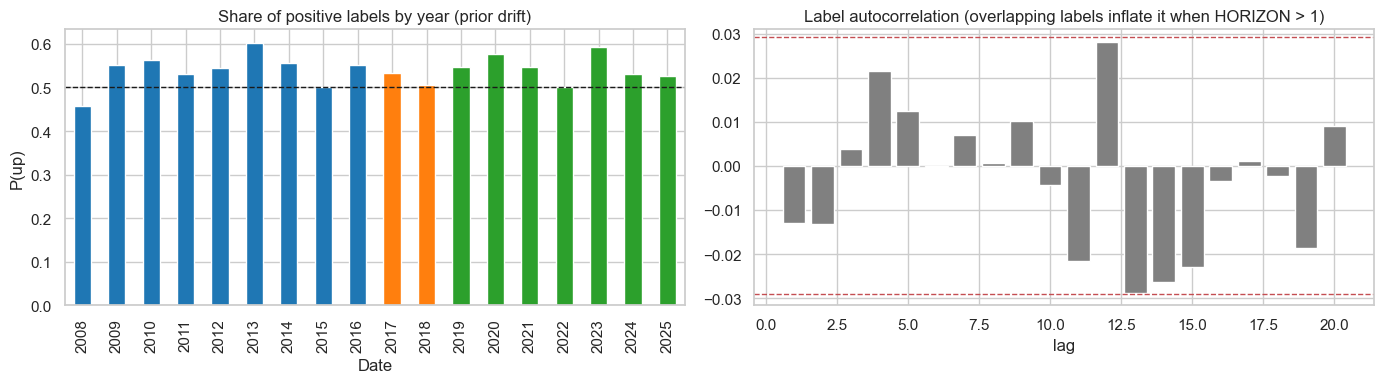

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
yr = data.groupby(data.index.year)["target"].mean()
yr.plot.bar(ax=ax[0], color=["tab:blue" if y <= 2016 else "tab:orange" if y <= 2018 else "tab:green" for y in yr.index])
ax[0].axhline(0.5, color="k", ls="--", lw=1)
ax[0].set_title("Share of positive labels by year (prior drift)"); ax[0].set_ylabel("P(up)")
ac = [data["target"].autocorr(l) for l in range(1, 21)]
ax[1].bar(range(1, 21), ac, color="gray")
ax[1].axhline(1.96 / np.sqrt(len(data)), ls="--", color="r", lw=1); ax[1].axhline(-1.96 / np.sqrt(len(data)), ls="--", color="r", lw=1)
ax[1].set_title("Label autocorrelation (overlapping labels inflate it when HORIZON > 1)"); ax[1].set_xlabel("lag")
plt.tight_layout(); savefig("label_drift"); plt.show()

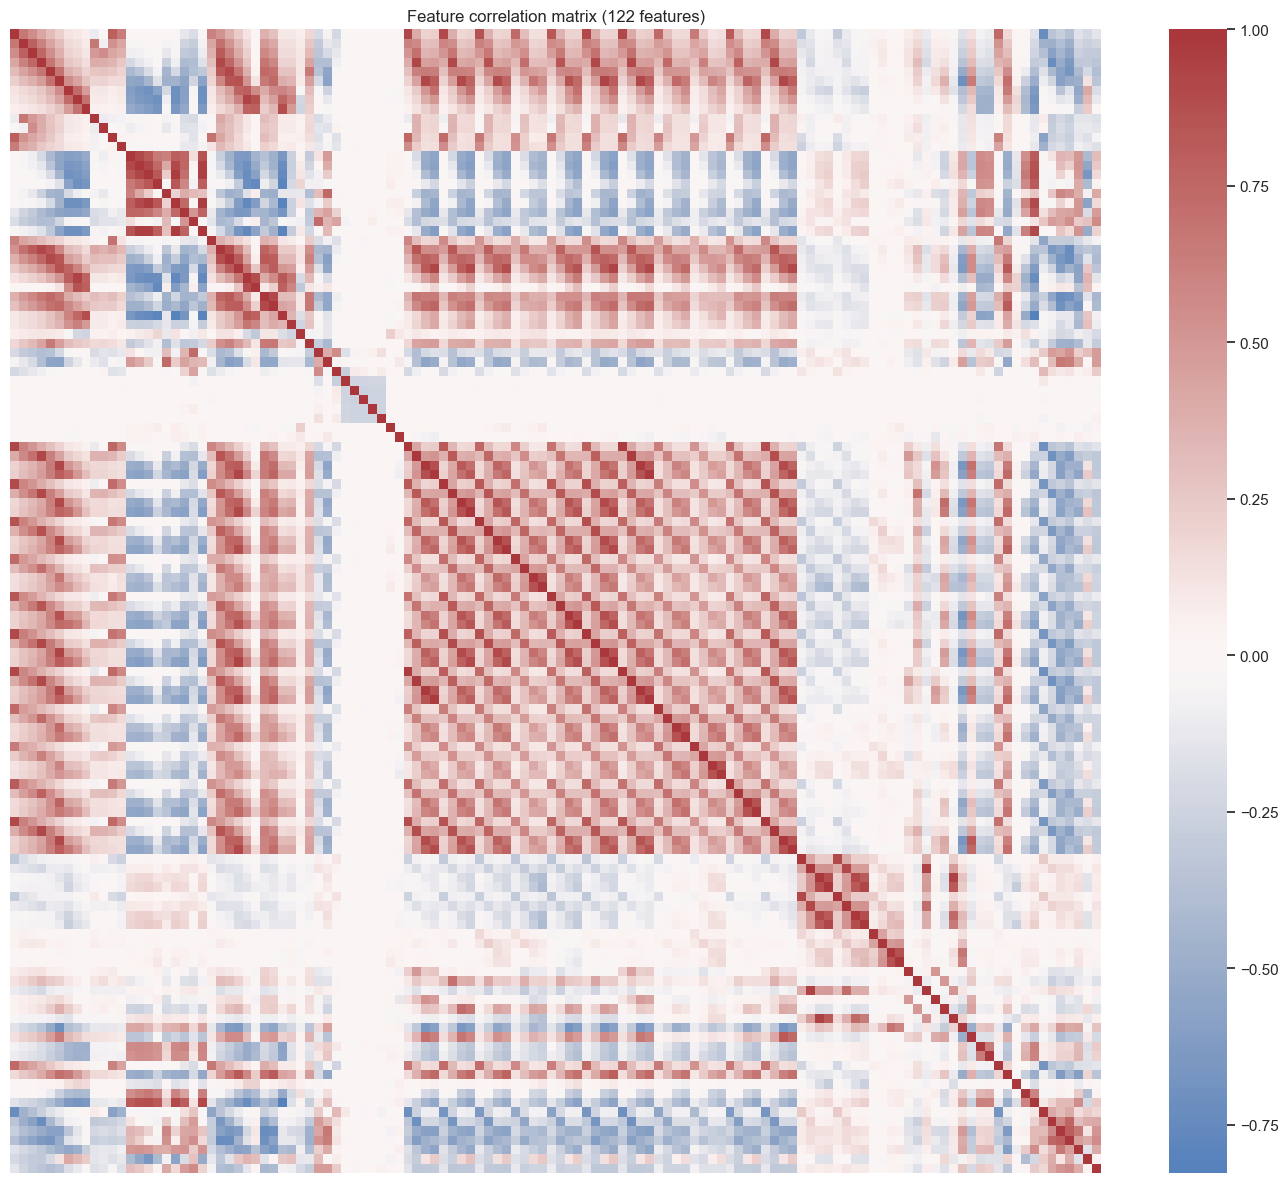

Most collinear pairs (handled by regularization / trees):
qqq_px_vs_sma50        xlk_px_vs_sma50         0.9766
qqq_ret_20d            xlk_ret_20d             0.9762
qqq_ret_5d             xlk_ret_5d              0.9713
spy_vol_20d            spy_parkinson_vol_20d   0.9702
qqq_ret_1d             xlk_ret_1d              0.9658
spy_parkinson_vol_20d  spy_atr14_pct           0.9652
spy_vol_20d            spy_atr14_pct           0.9557
spy_vol_10d            spy_atr14_pct           0.9528
tlt_ret_20d            tlt_minus_ief_ret_20d   0.9464
tlt_ret_5d             tlt_minus_ief_ret_5d    0.9456


In [13]:
corr = data[ALL_FEATURES].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="vlag", center=0, xticklabels=False, yticklabels=False)
plt.title(f"Feature correlation matrix ({len(ALL_FEATURES)} features)")
plt.tight_layout(); plt.show()
hi = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False))
print("Most collinear pairs (handled by regularization / trees):")
print(hi.head(10).to_string())

**Covariate drift.** The Population Stability Index (PSI) compares each feature's distribution in the test period with the training period, using deciles from the training data (PSI > 0.25 is conventionally a large shift). *Adversarial validation* trains a classifier to tell training-period rows from test-period rows. Its folds hold out whole calendar years, because shuffled folds would trivially match each day to its autocorrelated neighbours. An AUC well above 0.5 means the periods look systematically different.

  File "C:\Users\Amaur\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

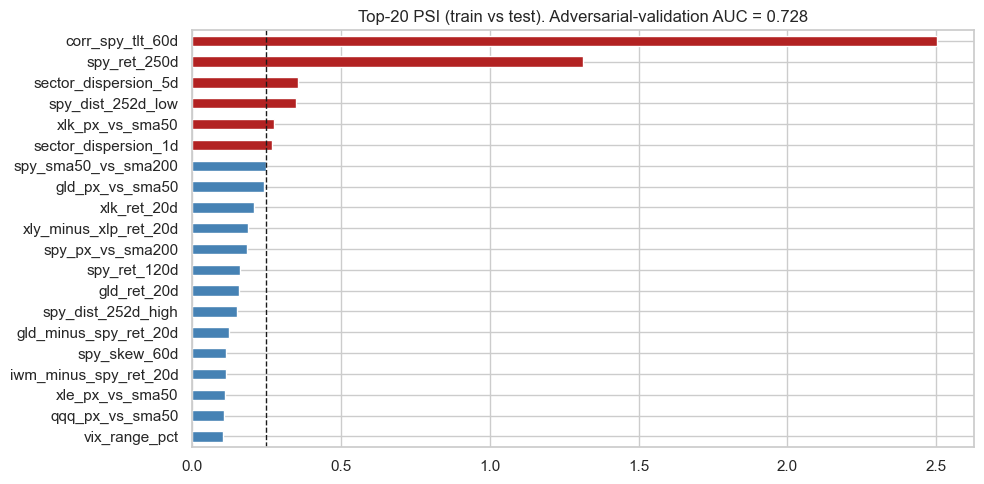

Features with PSI > 0.25: 6 / 122


In [14]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    q = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((q - p) * np.log(q / p)))

tr_mask, te_mask = data["split"].eq("train"), data["split"].eq("test")
psi_s = pd.Series({c: psi(data.loc[tr_mask, c], data.loc[te_mask, c]) for c in ALL_FEATURES}).sort_values(ascending=False)
psi_s.to_csv(RESULTS_DIR / "psi_train_vs_test.csv")

adv = data[tr_mask | te_mask]
adv_y = adv["split"].eq("test").astype(int)
# folds hold out whole calendar years; shuffled K-fold would leak via autocorrelated neighbouring days
adv_p = cross_val_predict(HistGradientBoostingClassifier(max_iter=200, random_state=SEED), adv[ALL_FEATURES], adv_y,
                          cv=GroupKFold(5), groups=adv.index.year, method="predict_proba")[:, 1]
adv_auc = roc_auc_score(adv_y, adv_p)

fig, ax = plt.subplots(figsize=(10, 5))
psi_s.head(20)[::-1].plot.barh(ax=ax, color=np.where(psi_s.head(20)[::-1] > 0.25, "firebrick", "steelblue"))
ax.axvline(0.25, ls="--", color="k", lw=1)
ax.set_title(f"Top-20 PSI (train vs test). Adversarial-validation AUC = {adv_auc:.3f}")
plt.tight_layout(); savefig("psi"); plt.show()
print(f"Features with PSI > 0.25: {(psi_s > 0.25).sum()} / {len(psi_s)}")

**Relationship drift.** Rolling 1-year Spearman correlations between selected features and the forward return show whether the *sign and strength* of predictive relationships are stable. Unstable relationships are the main reason to expect benefits from retraining.

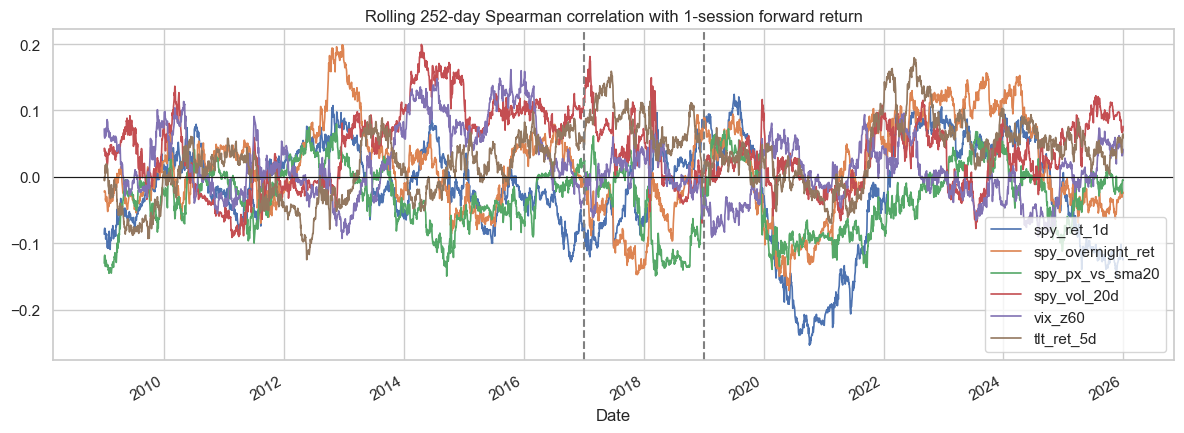

Number of sign changes of the rolling correlation:
 spy_ret_1d            80
spy_overnight_ret     78
spy_px_vs_sma20      176
spy_vol_20d          128
vix_z60              200
tlt_ret_5d           121


In [15]:
probe = ["spy_ret_1d", "spy_overnight_ret", "spy_px_vs_sma20", "spy_vol_20d", "vix_z60", "tlt_ret_5d"]
ranked = data[probe + ["fwd_ret"]].rank()
roll_corr = pd.DataFrame({c: ranked[c].rolling(252).corr(ranked["fwd_ret"]) for c in probe})
ax = roll_corr.plot(figsize=(12, 4.5), lw=1.2)
ax.axhline(0, color="k", lw=0.8)
for x in (TRAIN_END, VAL_END):
    ax.axvline(pd.Timestamp(x), color="gray", ls="--")
ax.set_title(f"Rolling 252-day Spearman correlation with {HORIZON}-session forward return")
plt.tight_layout(); savefig("rolling_feature_target_corr"); plt.show()
sign_changes = (np.sign(roll_corr.dropna()).diff().abs() > 0).sum()
print("Number of sign changes of the rolling correlation:\n", sign_changes.to_string())

## 7. Modeling framework: purged walk-forward engine

One function handles every experiment:

* **fixed**: fit once on all labeled data available at the start of the evaluation period, then predict the whole period.
* **expanding**: refit every *R* sessions on *all* labeled history available at that point.
* **rolling**: refit every *R* sessions on only the most recent *W* labeled observations.

At each refit date *t₀*, the training rows are those with `label_end ≤ t₀`, so no label is used before it is known.

**Classification threshold.** Models are trained without class weights, so their probabilities stay calibrated for the Brier score. A row is classified as *up* when the predicted probability is at least the **positive rate of the current training set**. This prior-matched threshold keeps the classifier from always predicting the majority class, which matters because balanced accuracy is the primary metric.

In [16]:
DATES = data.index
LABEL_END = data["label_end"].to_numpy()
Y = data["target"].to_numpy()
MASK = {s: data["split"].eq(s).to_numpy() for s in ["train", "val", "test"]}

def make_estimator(name, params=None):
    params = params or {}
    if name == "Majority":
        return DummyClassifier(strategy="prior")
    if name == "LogReg":
        return Pipeline([("scale", StandardScaler()),
                         ("clf", LogisticRegression(solver="saga", max_iter=5000, tol=1e-3, random_state=SEED, **params))])
    if name == "GBDT":
        return HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params)
    raise ValueError(name)

def walk_forward(estimator, cols, eval_mask, scheme="fixed", retrain_every=None, window=None, keep_models=False):
    X = data[cols].to_numpy()
    eval_pos = np.flatnonzero(eval_mask)
    if scheme == "fixed":
        blocks = [eval_pos]
    else:
        blocks = [eval_pos[i:i + retrain_every] for i in range(0, len(eval_pos), retrain_every)]
    proba, thr, refit = [], [], []
    models = []
    for b in blocks:
        t0 = DATES[b[0]]
        avail = np.flatnonzero(LABEL_END <= np.datetime64(t0))     # purging
        if scheme == "rolling":
            avail = avail[-window:]
        m = clone(estimator).fit(X[avail], Y[avail])
        proba.append(m.predict_proba(X[b])[:, 1])
        thr.append(np.full(len(b), Y[avail].mean()))
        refit.append(np.full(len(b), t0))
        if keep_models:
            models.append((t0, m))
    out = pd.DataFrame({"y": Y[eval_pos], "proba": np.concatenate(proba), "thr": np.concatenate(thr),
                        "refit_date": np.concatenate(refit)}, index=DATES[eval_pos])
    out["pred"] = (out["proba"] >= out["thr"]).astype(int)
    return (out, models) if keep_models else out

def metrics(pred):
    y, p, yhat = pred["y"], pred["proba"], pred["pred"]
    return {"balanced_acc": balanced_accuracy_score(y, yhat),
            "roc_auc": roc_auc_score(y, p) if y.nunique() > 1 else np.nan,
            "brier": brier_score_loss(y, p),
            "accuracy": accuracy_score(y, yhat),
            "pred_up_rate": yhat.mean(),
            "n": len(y)}

## 8. Hyperparameter tuning on the validation period

Each candidate is trained on 2008–2016 (purged) and scored on 2017–2018. Configurations that produce a **constant prediction** are excluded; this happens with strong L1 penalties, which zero out every coefficient and simply reproduce the majority baseline. Among the rest, the configuration with the highest validation **ROC-AUC** is selected, because AUC is threshold-free and less noisy than balanced accuracy on about 500 observations. As a stability check, the chosen configuration is also scored with `TimeSeriesSplit` (with a gap of `HORIZON` rows) inside the training period.

In [17]:
LR_GRID = [{"penalty": p, "C": C} for p in ["l1", "l2"] for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]]
GBDT_GRID = [{"learning_rate": lr, "max_depth": md, "max_iter": it, "min_samples_leaf": msl, "l2_regularization": l2}
             for lr in [0.03, 0.1] for md in [2, 3] for it in [100, 300]
             for msl in [50, 200] for l2 in [0.0, 1.0]]

def tune(name, grid, cols=ALL_FEATURES):
    rows = []
    for i, params in enumerate(grid):
        pred = walk_forward(make_estimator(name, params), cols, MASK["val"], "fixed")
        rows.append({"grid_id": i, **params, **metrics(pred),
                     "degenerate": pred["proba"].std() < 1e-6})   # constant prediction (e.g. all L1 coefs = 0)
    df = pd.DataFrame(rows).sort_values(["degenerate", SELECTION_METRIC], ascending=[True, False])
    if df.sort_values(SELECTION_METRIC, ascending=False).iloc[0]["degenerate"]:
        print(f"Note ({name}): a constant-prediction configuration had the best validation {SELECTION_METRIC}; "
              "i.e. no informative configuration beat AUC = 0.5 on validation. Constant configurations are excluded.")
    return df.reset_index(drop=True)

t = time.time()
tuning = {"LogReg": tune("LogReg", LR_GRID), "GBDT": tune("GBDT", GBDT_GRID)}
print(f"Tuning took {time.time() - t:.0f}s")
BEST_PARAMS = {"Majority": {}}
for name, df in tuning.items():
    grid = LR_GRID if name == "LogReg" else GBDT_GRID
    BEST_PARAMS[name] = grid[int(df.loc[0, "grid_id"])]
    df.to_csv(RESULTS_DIR / f"tuning_{name}.csv", index=False)
    print(f"\n{name} - top 5 configurations (validation):")
    display(df.head(5))
print("Selected:", BEST_PARAMS)

Note (LogReg): a constant-prediction configuration had the best validation roc_auc; i.e. no informative configuration beat AUC = 0.5 on validation. Constant configurations are excluded.


Tuning took 19s

LogReg - top 5 configurations (validation):


,grid_id,penalty,C,balanced_acc,roc_auc,brier,accuracy,pred_up_rate,n,degenerate
0,13,l2,1.0000,0.4935,0.4910,0.2613,0.4940,0.5120,502,False
1,12,l2,0.3000,0.4940,0.4886,0.2607,0.4940,0.5000,502,False
2,6,l1,1.0000,0.4854,0.4869,0.2600,0.4861,0.5159,502,False
3,11,l2,0.1000,0.4910,0.4859,0.2594,0.4900,0.4761,502,False
4,10,l2,0.0300,0.4760,0.4828,0.2567,0.4741,0.4522,502,False



GBDT - top 5 configurations (validation):


,grid_id,learning_rate,max_depth,max_iter,min_samples_leaf,l2_regularization,balanced_acc,roc_auc,brier,accuracy,pred_up_rate,n,degenerate
0,20,0.1000,2,300,50,0.0000,0.5240,0.5317,0.2563,0.5179,0.3486,502,False
1,17,0.1000,2,100,50,1.0000,0.5329,0.5233,0.2515,0.5259,0.3247,502,False
2,3,0.0300,2,100,200,1.0000,0.5119,0.5232,0.2497,0.5080,0.4024,502,False
3,21,0.1000,2,300,50,1.0000,0.5060,0.5226,0.2589,0.5000,0.3506,502,False
4,23,0.1000,2,300,200,1.0000,0.5173,0.5220,0.2585,0.5139,0.4163,502,False


Selected: {'Majority': {}, 'LogReg': {'penalty': 'l2', 'C': 1.0}, 'GBDT': {'learning_rate': 0.1, 'max_depth': 2, 'max_iter': 300, 'min_samples_leaf': 50, 'l2_regularization': 0.0}}


In [18]:
def tss_auc(name, params, cols=ALL_FEATURES, n_splits=5):
    tr = data[MASK["train"]]
    aucs = []
    for a, b in TimeSeriesSplit(n_splits=n_splits, gap=HORIZON).split(tr):
        m = make_estimator(name, params).fit(tr[cols].iloc[a], tr["target"].iloc[a])
        aucs.append(roc_auc_score(tr["target"].iloc[b], m.predict_proba(tr[cols].iloc[b])[:, 1]))
    return np.array(aucs)

for name in ["LogReg", "GBDT"]:
    a = tss_auc(name, BEST_PARAMS[name])
    print(f"{name:7s} TimeSeriesSplit AUC within 2008-2016: {np.round(a, 3)}  mean={a.mean():.3f}")

LogReg  TimeSeriesSplit AUC within 2008-2016: [0.558 0.47  0.51  0.516 0.491]  mean=0.509


GBDT    TimeSeriesSplit AUC within 2008-2016: [0.529 0.516 0.472 0.514 0.511]  mean=0.508


## 9. Selecting the retraining frequency and window on validation data

Every adaptation scheme is run walk-forward over the 2017–2018 validation period. Hyperparameters that suit a 9-year training set may overfit a 1-year rolling window, so each scheme is paired with each of the **top-`TOP_K` hyperparameter configurations** from Section 8. For each model, the selection by validation AUC picks:
* the best hyperparameters for the fixed scheme,
* the best (*R*, hyperparameters) for the expanding scheme,
* the best (*W*, *R*, hyperparameters) for the rolling scheme.

The test period is never used for these choices.

The majority baseline has no features. Its "adaptive" variants simply track the recent base rate, using *R* = 21 with an expanding window or a 252-session rolling window.

In [19]:
TOP_K = 4
SCHEME_GRID = ([("fixed", None, None)] +
               [("expanding", R, None) for R in RETRAIN_EVERY_GRID] +
               [("rolling", R, W) for R in RETRAIN_EVERY_GRID for W in ROLLING_WINDOW_GRID])
CANDIDATES = {}
for name in ["LogReg", "GBDT"]:
    grid = LR_GRID if name == "LogReg" else GBDT_GRID
    ok = tuning[name][~tuning[name]["degenerate"]]
    CANDIDATES[name] = [grid[int(i)] for i in ok["grid_id"].head(TOP_K)]

t = time.time()
rows = []
for name in ["LogReg", "GBDT"]:
    for cand_id, params in enumerate(CANDIDATES[name]):
        est = make_estimator(name, params)
        for scheme, R, W in SCHEME_GRID:
            m = metrics(walk_forward(est, ALL_FEATURES, MASK["val"], scheme, R, W))
            rows.append({"model": name, "scheme": scheme, "retrain_every": R, "window": W,
                         "cand_id": cand_id, "params": str(params), **m})
val_schemes = pd.DataFrame(rows)
val_schemes.to_csv(RESULTS_DIR / "validation_scheme_selection.csv", index=False)
print(f"Scheme x hyperparameter search ({len(rows)} walk-forward runs) took {time.time() - t:.0f}s")

# (retrain_every, window, hyperparameters); the baseline only tracks the recent base rate
CHOSEN = {"Majority": {"fixed": (None, None, {}), "expanding": (21, None, {}), "rolling": (21, 252, {})}}
best_rows = []
for (name, scheme), gs in val_schemes.groupby(["model", "scheme"]):
    best = gs.sort_values(SELECTION_METRIC, ascending=False).iloc[0]
    CHOSEN.setdefault(name, {})[scheme] = (None if pd.isna(best.retrain_every) else int(best.retrain_every),
                                           None if pd.isna(best.window) else int(best.window),
                                           CANDIDATES[name][int(best.cand_id)])
    best_rows.append(best)
display(pd.DataFrame(best_rows)[["model", "scheme", "retrain_every", "window", "params", "roc_auc", "balanced_acc", "brier"]]
        .reset_index(drop=True))
print("Validation AUC by scheme configuration (best hyperparameter candidate for each):")
display(val_schemes.assign(retrain_every=val_schemes.retrain_every.fillna(0).astype(int),
                           window=val_schemes.window.fillna(0).astype(int))
        .pivot_table(index=["scheme", "retrain_every", "window"], columns="model", values="roc_auc", aggfunc="max").round(4))

Scheme x hyperparameter search (88 walk-forward runs) took 500s


,model,scheme,retrain_every,window,params,roc_auc,balanced_acc,brier
0,GBDT,expanding,21.0000,NaN,"{'learning_rate': 0.03, 'max_depth': 2, 'max_i...",0.5214,0.5283,0.2496
1,GBDT,fixed,NaN,NaN,"{'learning_rate': 0.1, 'max_depth': 2, 'max_it...",0.5317,0.5240,0.2563
2,GBDT,rolling,21.0000,"1,008.0000","{'learning_rate': 0.03, 'max_depth': 2, 'max_i...",0.5331,0.5074,0.2489
3,LogReg,expanding,63.0000,NaN,"{'penalty': 'l2', 'C': 1.0}",0.4853,0.4816,0.2617
4,LogReg,fixed,NaN,NaN,"{'penalty': 'l2', 'C': 1.0}",0.4910,0.4935,0.2613
5,LogReg,rolling,63.0000,"1,008.0000","{'penalty': 'l2', 'C': 1.0}",0.5215,0.5135,0.2971


Validation AUC by scheme configuration (best hyperparameter candidate for each):


model                            GBDT  LogReg
scheme    retrain_every window               
expanding 21            0      0.5214  0.4830
          63            0      0.5162  0.4853
fixed     0             0      0.5317  0.4910
rolling   21            252    0.5215  0.4529
                        504    0.5261  0.4641
                        1008   0.5331  0.4966
                        1512   0.4837  0.5010
          63            252    0.5171  0.4532
                        504    0.5218  0.4786
                        1008   0.5133  0.5215
                        1512   0.4900  0.5005

## 10. Main experiment: walk-forward evaluation on the test period (2019–2025)

Every model × scheme combination is evaluated on the same test observations. The **fixed** models are trained once on all labeled data through 2018 (train + validation), so they start the test period with the same information as the adaptive models. The adaptive models then keep updating.

The same loop also runs the **SPY-only** feature set for the cross-market ablation in Section 13.

In [20]:
FEATURE_SETS = {"all": ALL_FEATURES, "spy_only": SPY_FEATURES}
SCHEMES = ["fixed", "expanding", "rolling"]
MODELS = ["Majority", "LogReg", "GBDT"]
runs, lr_models = {}, {}
t = time.time()
for fs, cols in FEATURE_SETS.items():
    for name in MODELS:
        if name == "Majority" and fs != "all":
            continue
        for scheme in SCHEMES:
            R, W, params = CHOSEN[name][scheme]
            est = make_estimator(name, params)
            if name == "LogReg" and fs == "all":
                runs[(fs, name, scheme)], lr_models[scheme] = walk_forward(est, cols, MASK["test"], scheme, R, W, keep_models=True)
            else:
                runs[(fs, name, scheme)] = walk_forward(est, cols, MASK["test"], scheme, R, W)
print(f"Walk-forward test runs: {len(runs)} in {time.time() - t:.0f}s")

pred_long = pd.concat({k: v for k, v in runs.items()}, names=["features", "model", "scheme", "date"])
pred_long.to_csv(RESULTS_DIR / "test_predictions.csv")

Walk-forward test runs: 15 in 162s


In [21]:
res = pd.DataFrame({k: metrics(v) for k, v in runs.items()}).T
res.index.names = ["features", "model", "scheme"]
base_brier = res.loc[("all", "Majority", "fixed"), "brier"]
res["brier_skill"] = 1 - res["brier"] / base_brier
res.to_csv(RESULTS_DIR / "test_metrics.csv")
main = res.loc["all"].reindex(pd.MultiIndex.from_product([MODELS, SCHEMES], names=["model", "scheme"]))
print(f"TEST PERIOD {DATES[MASK['test']].min().date()} -> {DATES[MASK['test']].max().date()}, "
      f"horizon = {HORIZON}, all features")
main.style.format("{:.4f}", subset=["balanced_acc", "roc_auc", "brier", "accuracy", "pred_up_rate", "brier_skill"]) \
    .format("{:.0f}", subset=["n"]) \
    .highlight_max(subset=["balanced_acc", "roc_auc"], color="#c6efce") \
    .highlight_min(subset=["brier"], color="#c6efce")

TEST PERIOD 2019-01-02 -> 2025-12-30, horizon = 1, all features


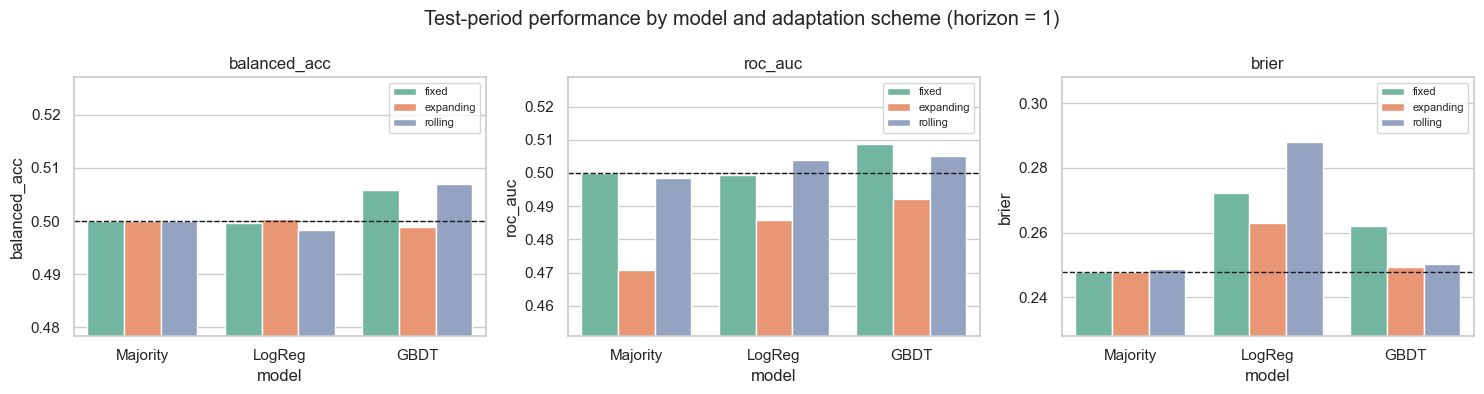

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_df = main.reset_index()
for ax, m, ref in zip(axes, ["balanced_acc", "roc_auc", "brier"], [0.5, 0.5, base_brier]):
    sns.barplot(data=plot_df, x="model", y=m, hue="scheme", ax=ax, palette="Set2")
    ax.axhline(ref, color="k", ls="--", lw=1)
    lo, hi = plot_df[m].min(), plot_df[m].max()
    ax.set_ylim(lo - 0.02, hi + 0.02); ax.set_title(m); ax.legend(fontsize=8)
plt.suptitle(f"Test-period performance by model and adaptation scheme (horizon = {HORIZON})")
plt.tight_layout(); savefig("test_metrics_bar"); plt.show()

## 11. Statistical comparison: paired moving-block bootstrap

Daily financial outcomes are serially dependent, and labels overlap when the horizon is longer than one session. Ordinary i.i.d. confidence intervals would therefore be too narrow. We resample contiguous blocks of `BLOCK_LEN` test days. Both models in a comparison are evaluated on the same resampled days (paired), which yields a 95% CI for the **improvement** of model A over model B. A positive value means A is better; for the Brier score, the sign is flipped. The one-sided *p* is the share of bootstrap draws with no improvement.

In [23]:
def block_indices(n, L, rng):
    starts = rng.integers(0, n - L + 1, int(np.ceil(n / L)))
    return (starts[:, None] + np.arange(L)).ravel()[:n]

def fast_scores(y, p, yhat):
    ba = 0.5 * (yhat[y == 1].mean() + (1 - yhat[y == 0]).mean())
    return np.array([ba, roc_auc_score(y, p), np.mean((p - y) ** 2)])

def paired_bootstrap(a, b, n_boot=N_BOOT, L=BLOCK_LEN, seed=SEED):
    rng = np.random.default_rng(seed)
    y, pa, ya, pb, yb = (a["y"].to_numpy(), a["proba"].to_numpy(), a["pred"].to_numpy(),
                         b["proba"].to_numpy(), b["pred"].to_numpy())
    sign = np.array([1, 1, -1])                       # positive = A better
    point = sign * (fast_scores(y, pa, ya) - fast_scores(y, pb, yb))
    draws = np.empty((n_boot, 3))
    for i in range(n_boot):
        idx = block_indices(len(y), L, rng)
        draws[i] = sign * (fast_scores(y[idx], pa[idx], ya[idx]) - fast_scores(y[idx], pb[idx], yb[idx]))
    out = {}
    for j, mname in enumerate(["balanced_acc", "roc_auc", "brier"]):
        out[(mname, "improvement")] = point[j]
        out[(mname, "ci_low")] = np.percentile(draws[:, j], 2.5)
        out[(mname, "ci_high")] = np.percentile(draws[:, j], 97.5)
        out[(mname, "p_one_sided")] = np.mean(draws[:, j] <= 0)
    return out

comparisons = {}
for name in ["LogReg", "GBDT"]:
    for s in ["expanding", "rolling"]:
        comparisons[f"{name}: {s} vs fixed"] = (("all", name, s), ("all", name, "fixed"))
    for s in SCHEMES:
        # always vs the trained-once baseline: a refit Majority changes its constant at each refit,
        # which pushes its pooled AUC below 0.5 and would flatter the ML models
        comparisons[f"{name}: {s} vs Majority"] = (("all", name, s), ("all", "Majority", "fixed"))
        comparisons[f"{name}: all vs SPY-only features ({s})"] = (("all", name, s), ("spy_only", name, s))
t = time.time()
boot = pd.DataFrame({k: paired_bootstrap(runs[a], runs[b]) for k, (a, b) in comparisons.items()}).T
boot.columns = pd.MultiIndex.from_tuples(boot.columns)
boot.to_csv(RESULTS_DIR / "bootstrap_comparisons.csv")
print(f"Bootstrap ({N_BOOT} draws, block length {BLOCK_LEN}) took {time.time() - t:.0f}s")
boot.round(4)

Bootstrap (1000 draws, block length 20) took 45s


balanced_acc                                 roc_auc                                   brier                            
                                              improvement  ci_low ci_high p_one_sided improvement  ci_low ci_high p_one_sided improvement  ci_low ci_high p_one_sided
LogReg: expanding vs fixed                         0.0009 -0.0171  0.0193      0.4770     -0.0136 -0.0295  0.0016      0.9550      0.0092  0.0039  0.0154      0.0000
LogReg: rolling vs fixed                          -0.0013 -0.0311  0.0274      0.5760      0.0044 -0.0281  0.0381      0.4160     -0.0159 -0.0284 -0.0019      0.9900
LogReg: fixed vs Majority                         -0.0004 -0.0215  0.0234      0.4970     -0.0005 -0.0260  0.0277      0.5080     -0.0242 -0.0337 -0.0158      1.0000
LogReg: all vs SPY-only features (fixed)           0.0058 -0.0200  0.0365      0.2930      0.0107 -0.0150  0.0399      0.1910     -0.0199 -0.0284 -0.0122      1.0000
LogReg: expanding vs Majority                      0.0005 -0.0214  0.0230      0.4720     -0.0140 -0.0384  0.0132      0.8480     -0.0150 -0.0218 -0.0086      1.0000
LogReg: all vs SPY-only features (expanding)       0.0110 -0.0146  0.0394      0.2010     -0.0018 -0.0268  0.0258      0.5110     -0.0116 -0.0171 -0.0063      1.0000
LogReg: rolling vs Majority                       -0.0017 -0.0241  0.0179      0.5950      0.0039 -0.0193  0.0295      0.3740     -0.0400 -0.0529 -0.0276      1.0000
LogReg: all vs SPY-only features (rolling)         0.0098 -0.0163  0.0338      0.2370      0.0144 -0.0070  0.0432      0.0980     -0.0228 -0.0317 -0.0129      1.0000
GBDT: expanding vs fixed                          -0.0070 -0.0328  0.0182      0.7110     -0.0165 -0.0448  0.0071      0.9100      0.0127  0.0068  0.0174      0.0000
GBDT: rolling vs fixed                             0.0012 -0.0301  0.0284      0.4870     -0.0038 -0.0406  0.0256      0.6360      0.0118  0.0050  0.0173      0.0000
GBDT: fixed vs Majority                            0.0058 -0.0179  0.0310      0.3090      0.0088 -0.0162  0.0392      0.2310     -0.0140 -0.0195 -0.0075      1.0000
GBDT: all vs SPY-only features (fixed)             0.0018 -0.0252  0.0310      0.4240      0.0064 -0.0218  0.0379      0.2790     -0.0004 -0.0063  0.0064      0.5010
GBDT: expanding vs Majority                       -0.0012 -0.0252  0.0217      0.5160     -0.0078 -0.0336  0.0195      0.6990     -0.0014 -0.0027  0.0001      0.9680
GBDT: all vs SPY-only features (expanding)         0.0082 -0.0166  0.0315      0.2770      0.0081 -0.0169  0.0349      0.2960      0.0001 -0.0012  0.0013      0.4740
GBDT: rolling vs Majority                          0.0071 -0.0149  0.0276      0.2700      0.0050 -0.0214  0.0281      0.3470     -0.0022 -0.0048  0.0000      0.9730
GBDT: all vs SPY-only features (rolling)           0.0114 -0.0152  0.0397      0.1860      0.0111 -0.0151  0.0399      0.2070      0.0004 -0.0019  0.0032      0.3670

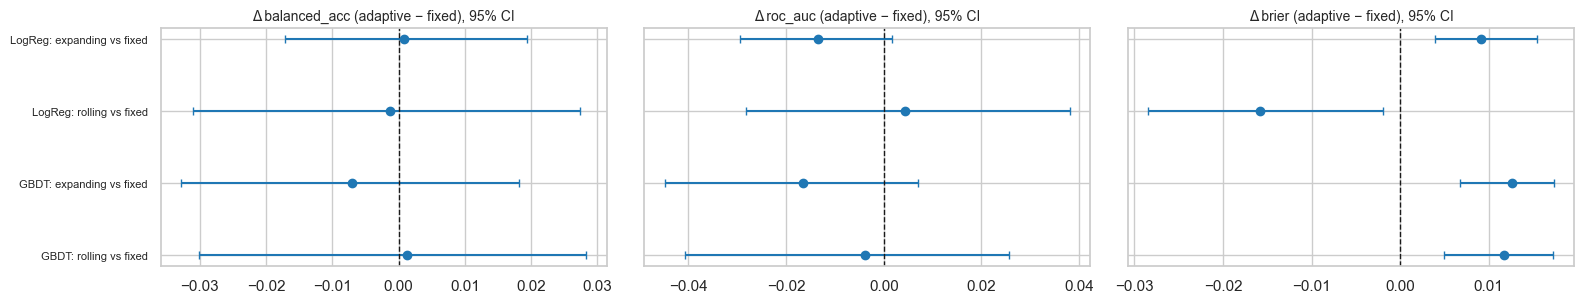

In [24]:
def plot_ci(rows, metric, ax, title):
    sub = boot.loc[rows, metric]
    yy = np.arange(len(sub))[::-1]
    ax.errorbar(sub["improvement"], yy, xerr=[sub["improvement"] - sub["ci_low"], sub["ci_high"] - sub["improvement"]],
                fmt="o", capsize=3, color="tab:blue")
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.set_yticks(yy); ax.set_yticklabels(sub.index, fontsize=8); ax.set_title(title, fontsize=10)

drift_rows = [k for k in comparisons if "vs fixed" in k]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), sharey=True)
for ax, m in zip(axes, ["balanced_acc", "roc_auc", "brier"]):
    plot_ci(drift_rows, m, ax, f"Δ {m} (adaptive − fixed), 95% CI")
plt.tight_layout(); savefig("bootstrap_adaptive_vs_fixed"); plt.show()

## 12. Performance over time, by volatility regime, and by year

A single test-period average can hide drift. We look at:
* **rolling 252-session** balanced accuracy and AUC through time;
* metrics within **VIX regimes**, using terciles defined on the *training* period (low / medium / high volatility);
* **per-year** balanced accuracy.

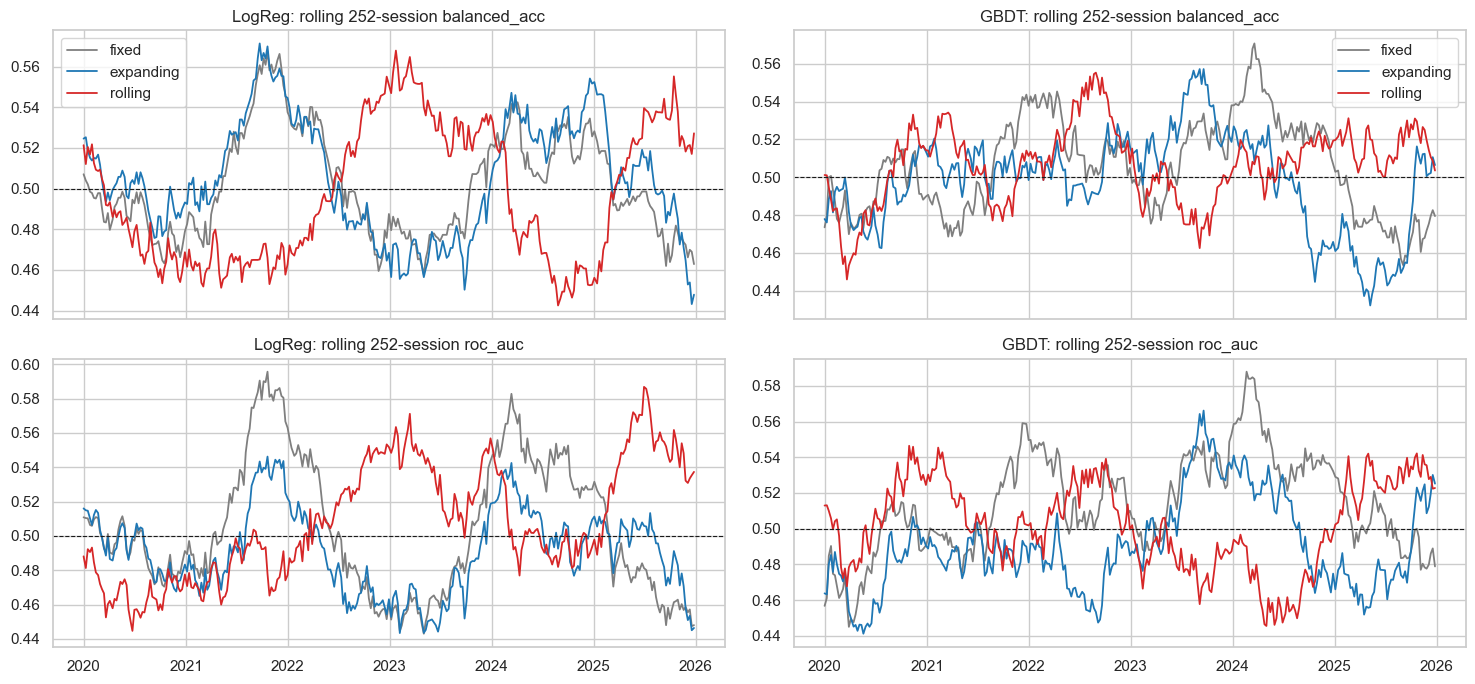

In [25]:
def rolling_metric(pred, w=252, step=5):
    y, p, yh = pred["y"].to_numpy(), pred["proba"].to_numpy(), pred["pred"].to_numpy()
    out = {}
    for end in range(w, len(y) + 1, step):
        s = slice(end - w, end)
        if len(np.unique(y[s])) < 2:
            continue
        out[pred.index[end - 1]] = fast_scores(y[s], p[s], yh[s])[:2]
    return pd.DataFrame(out, index=["balanced_acc", "roc_auc"]).T

fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
colors = dict(zip(SCHEMES, ["tab:gray", "tab:blue", "tab:red"]))
for j, name in enumerate(["LogReg", "GBDT"]):
    for s in SCHEMES:
        rm = rolling_metric(runs[("all", name, s)])
        for i, m in enumerate(["balanced_acc", "roc_auc"]):
            axes[i, j].plot(rm[m], label=s, color=colors[s], lw=1.3)
    for i, m in enumerate(["balanced_acc", "roc_auc"]):
        axes[i, j].axhline(0.5, color="k", ls="--", lw=0.8)
        axes[i, j].set_title(f"{name}: rolling 252-session {m}")
    axes[0, j].legend()
plt.tight_layout(); savefig("rolling_performance"); plt.show()

VIX tercile cut-offs from training period: 15.6, 21.6


balanced_acc                        n                    roc_auc                
regime                 high VIX low VIX mid VIX high VIX  low VIX  mid VIX high VIX low VIX mid VIX
model    scheme                                                                                    
GBDT     expanding       0.5080  0.5090  0.4850 551.0000 486.0000 722.0000   0.4970  0.4980  0.4840
         fixed           0.4970  0.5180  0.5050 551.0000 486.0000 722.0000   0.5120  0.5120  0.5060
         rolling         0.5310  0.5150  0.4830 551.0000 486.0000 722.0000   0.5310  0.4950  0.4930
LogReg   expanding       0.4750  0.4940  0.5240 551.0000 486.0000 722.0000   0.4560  0.4760  0.5200
         fixed           0.4730  0.4900  0.5260 551.0000 486.0000 722.0000   0.4660  0.4990  0.5270
         rolling         0.5040  0.4850  0.5030 551.0000 486.0000 722.0000   0.5100  0.4860  0.5110
Majority expanding       0.5000  0.5000  0.5000 551.0000 486.0000 722.0000   0.4770  0.4760  0.4620
         fixed           0.5000  0.5000  0.5000 551.0000 486.0000 722.0000   0.5000  0.5000  0.5000
         rolling         0.5000  0.5000  0.5000 551.0000 486.0000 722.0000   0.5100  0.4980  0.4910

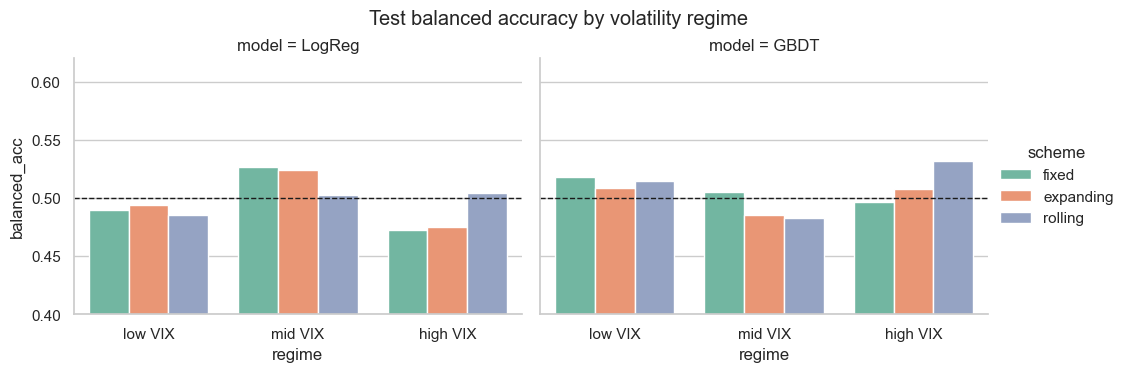

In [26]:
vix_tr = data.loc[MASK["train"], "vix_level"]
q1, q2 = vix_tr.quantile([1 / 3, 2 / 3])
regime = pd.cut(data["vix_level"], [-np.inf, q1, q2, np.inf], labels=["low VIX", "mid VIX", "high VIX"])
print(f"VIX tercile cut-offs from training period: {q1:.1f}, {q2:.1f}")

rows = []
for (fs, name, s), pred in runs.items():
    if fs != "all":
        continue
    for r, g in pred.groupby(regime.loc[pred.index], observed=True):
        rows.append({"model": name, "scheme": s, "regime": r, **metrics(g)})
by_regime = pd.DataFrame(rows)
by_regime.to_csv(RESULTS_DIR / "metrics_by_vix_regime.csv", index=False)
display(by_regime.pivot_table(index=["model", "scheme"], columns="regime", values=["balanced_acc", "roc_auc", "n"],
                              observed=True).round(3))

g = sns.catplot(data=by_regime[by_regime.model != "Majority"], x="regime", y="balanced_acc", hue="scheme",
                col="model", kind="bar", palette="Set2", height=3.6, aspect=1.4)
for ax in g.axes.flat:
    ax.axhline(0.5, color="k", ls="--", lw=1); ax.set_ylim(0.4, 0.62)
g.fig.suptitle("Test balanced accuracy by volatility regime", y=1.03)
plt.savefig(RESULTS_DIR / "by_vix_regime.png", bbox_inches="tight"); plt.show()

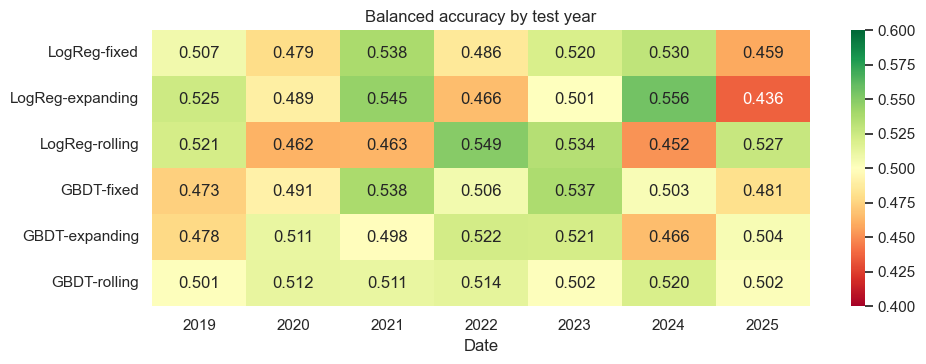

In [27]:
by_year = pd.DataFrame({f"{n}-{s}": pred.groupby(pred.index.year).apply(lambda g: metrics(g)["balanced_acc"])
                        for (fs, n, s), pred in runs.items() if fs == "all" and n != "Majority"}).T
plt.figure(figsize=(10, 3.8))
sns.heatmap(by_year, annot=True, fmt=".3f", cmap="RdYlGn", center=0.5, vmin=0.4, vmax=0.6)
plt.title("Balanced accuracy by test year"); plt.tight_layout(); savefig("by_year"); plt.show()

## 13. Cross-market feature ablation

Do related markets (other ETFs, bonds, gold, VIX) add predictive value beyond SPY's own history? The table compares the full feature set with the SPY-only set under each scheme. Bootstrap CIs are included in the Section 11 table (rows "all vs SPY-only features").

In [28]:
abl = res.drop(index=("all", "Majority"), errors="ignore")[["balanced_acc", "roc_auc", "brier"]].unstack("features")
abl = abl.swaplevel(axis=1).sort_index(axis=1)
for m in ["balanced_acc", "roc_auc", "brier"]:
    abl[("Δ all−spy_only", m)] = abl[("all", m)] - abl[("spy_only", m)]
display(abl.round(4))
display(boot.loc[[k for k in comparisons if "SPY-only" in k]].round(4))

features                  all                    spy_only                Δ all−spy_only                
                 balanced_acc  brier roc_auc balanced_acc  brier roc_auc   balanced_acc roc_auc   brier
model  scheme                                                                                          
LogReg expanding       0.5005 0.2630  0.4860       0.4894 0.2514  0.4877         0.0110 -0.0018  0.0116
       fixed           0.4996 0.2721  0.4995       0.4938 0.2522  0.4888         0.0058  0.0107  0.0199
       rolling         0.4983 0.2880  0.5039       0.4886 0.2652  0.4895         0.0098  0.0144  0.0228
GBDT   expanding       0.4988 0.2493  0.4922       0.4906 0.2494  0.4841         0.0082  0.0081 -0.0001
       fixed           0.5058 0.2620  0.5088       0.5040 0.2615  0.5024         0.0018  0.0064  0.0004
       rolling         0.5071 0.2502  0.5050       0.4957 0.2506  0.4939         0.0114  0.0111 -0.0004

balanced_acc                                 roc_auc                                   brier                            
                                              improvement  ci_low ci_high p_one_sided improvement  ci_low ci_high p_one_sided improvement  ci_low ci_high p_one_sided
LogReg: all vs SPY-only features (fixed)           0.0058 -0.0200  0.0365      0.2930      0.0107 -0.0150  0.0399      0.1910     -0.0199 -0.0284 -0.0122      1.0000
LogReg: all vs SPY-only features (expanding)       0.0110 -0.0146  0.0394      0.2010     -0.0018 -0.0268  0.0258      0.5110     -0.0116 -0.0171 -0.0063      1.0000
LogReg: all vs SPY-only features (rolling)         0.0098 -0.0163  0.0338      0.2370      0.0144 -0.0070  0.0432      0.0980     -0.0228 -0.0317 -0.0129      1.0000
GBDT: all vs SPY-only features (fixed)             0.0018 -0.0252  0.0310      0.4240      0.0064 -0.0218  0.0379      0.2790     -0.0004 -0.0063  0.0064      0.5010
GBDT: all vs SPY-only features (expanding)         0.0082 -0.0166  0.0315      0.2770      0.0081 -0.0169  0.0349      0.2960      0.0001 -0.0012  0.0013      0.4740
GBDT: all vs SPY-only features (rolling)           0.0114 -0.0152  0.0397      0.1860      0.0111 -0.0151  0.0399      0.2070      0.0004 -0.0019  0.0032      0.3670

## 14. Model interpretation & calibration

* **Logistic-regression coefficients over time** (standardized features). If the important coefficients wander or flip sign across refits, that is direct evidence of concept drift, which an adaptive model can follow and a fixed one cannot.
* **Permutation importance** of the fixed GBDT on the test set (drop in AUC when a feature is shuffled).
* **Reliability diagram**: are the predicted probabilities calibrated?

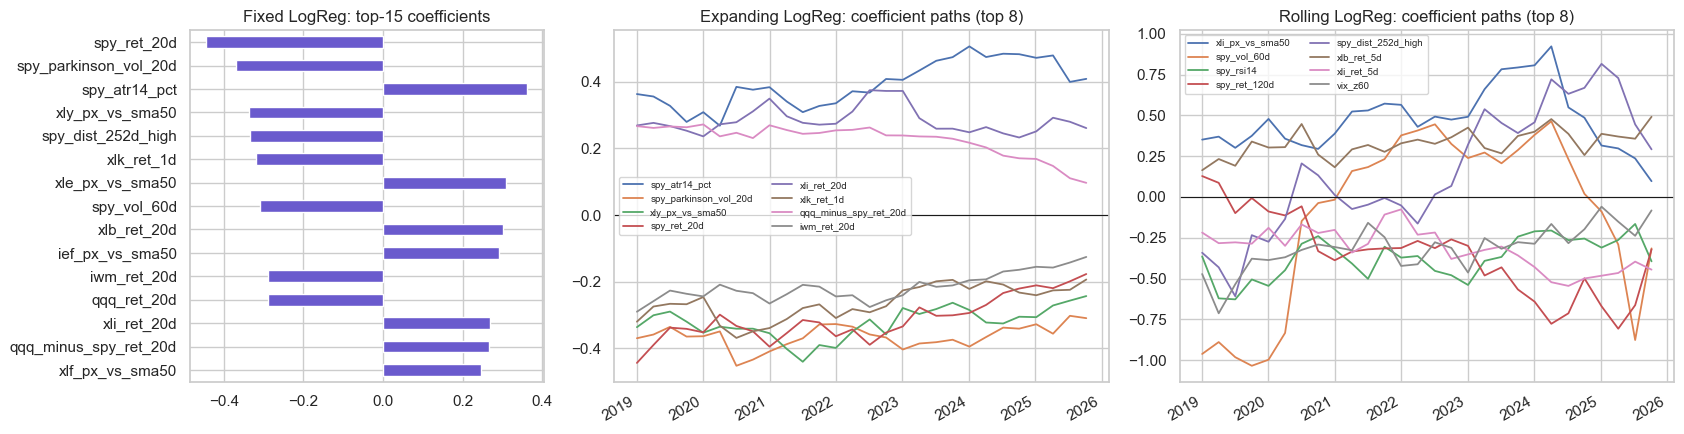

expanding: 28 refits; features whose coefficient flipped sign at least once: 49
rolling: 28 refits; features whose coefficient flipped sign at least once: 112


In [29]:
def lr_coefs(models, cols=ALL_FEATURES):
    return pd.DataFrame({pd.Timestamp(t0): m.named_steps["clf"].coef_.ravel() for t0, m in models}, index=cols).T

fixed_coef = lr_coefs(lr_models["fixed"]).iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
fixed_coef.reindex(fixed_coef.abs().sort_values(ascending=False).index[:15])[::-1].plot.barh(ax=axes[0], color="slateblue")
axes[0].set_title("Fixed LogReg: top-15 coefficients")
for ax, s in zip(axes[1:], ["expanding", "rolling"]):
    cf = lr_coefs(lr_models[s])
    top = cf.abs().mean().sort_values(ascending=False).index[:8]
    cf[top].plot(ax=ax, lw=1.3); ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{s.capitalize()} LogReg: coefficient paths (top 8)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); savefig("lr_coefficients"); plt.show()

for s in ["expanding", "rolling"]:
    cf = lr_coefs(lr_models[s])
    nz = cf.loc[:, (cf != 0).any()]
    flips = ((np.sign(nz).diff().abs() == 2).sum()).sort_values(ascending=False)
    print(f"{s}: {len(cf)} refits; features whose coefficient flipped sign at least once: {(flips > 0).sum()}")

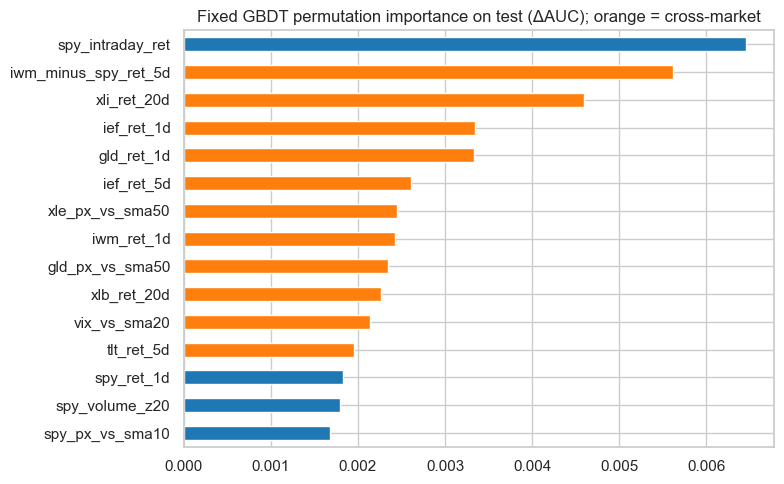

In [30]:
gbdt_fixed = make_estimator("GBDT", CHOSEN["GBDT"]["fixed"][2]).fit(
    data.loc[LABEL_END <= np.datetime64(DATES[MASK["test"]][0]), ALL_FEATURES],
    data.loc[LABEL_END <= np.datetime64(DATES[MASK["test"]][0]), "target"])
Xte, yte = data.loc[MASK["test"], ALL_FEATURES], data.loc[MASK["test"], "target"]
pi = permutation_importance(gbdt_fixed, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
pi_s.to_csv(RESULTS_DIR / "gbdt_permutation_importance.csv")
ax = pi_s.head(15)[::-1].plot.barh(figsize=(8, 5), color=["tab:orange" if c in CROSS_FEATURES else "tab:blue" for c in pi_s.head(15)[::-1].index])
ax.set_title("Fixed GBDT permutation importance on test (ΔAUC); orange = cross-market")
plt.tight_layout(); savefig("gbdt_permutation_importance"); plt.show()

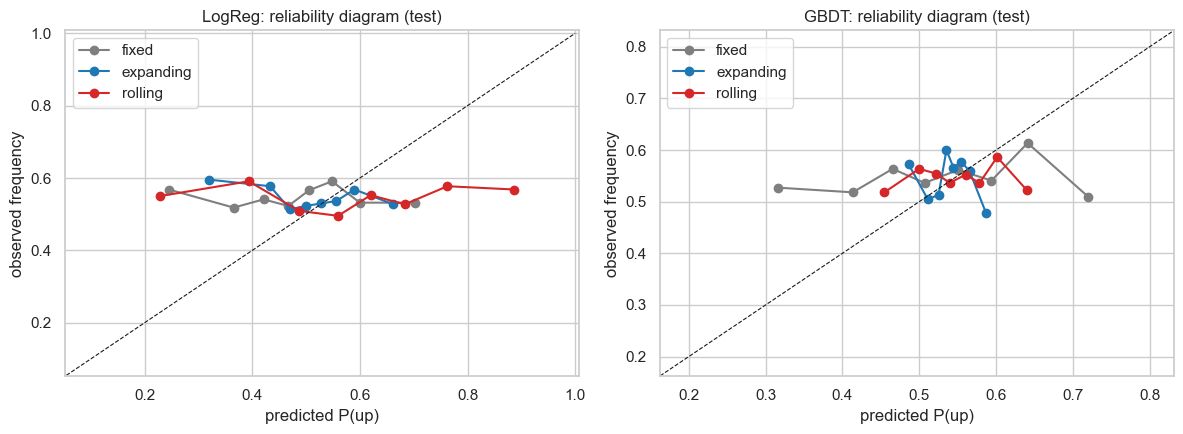

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["LogReg", "GBDT"]):
    for s in SCHEMES:
        p = runs[("all", name, s)]
        fy, fx = calibration_curve(p["y"], p["proba"], n_bins=8, strategy="quantile")
        ax.plot(fx, fy, "o-", label=s, color=colors[s])
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    lo = min(p["proba"].quantile(0.01) for p in [runs[("all", name, s)] for s in SCHEMES]) - 0.05
    hi = max(p["proba"].quantile(0.99) for p in [runs[("all", name, s)] for s in SCHEMES]) + 0.05
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f"{name}: reliability diagram (test)"); ax.set_xlabel("predicted P(up)"); ax.set_ylabel("observed frequency"); ax.legend()
plt.tight_layout(); savefig("calibration"); plt.show()

## 15. Exploratory trading simulation (not used for the main conclusions)

Each signal at the close of *t* is acted on by buying (or shorting) at the next **open** and closing the position at the next **close**. All positions are intraday.

* **Long/flat**: hold SPY when the model predicts *up*, otherwise stay in cash (0% return).
* **Long/short**: long when the model predicts *up*, short otherwise.
* **Always long (same windows)**: the benchmark, which holds over exactly the same windows and pays the same costs.

A round-trip cost (in basis points) is charged on every trade. No risk-free rate is assumed, the Sharpe ratio is annualized, and the results ignore slippage, borrow costs and taxes.

In [32]:
PERIODS_PER_YEAR = 252 / HORIZON

def backtest(pred, cost_bps, mode="long_flat"):
    p = pred.iloc[::HORIZON]                                # non-overlapping holding periods
    r = data.loc[p.index, "fwd_ret"]
    if mode == "always_long":
        pos = pd.Series(1.0, index=p.index)
    elif mode == "long_flat":
        pos = p["pred"].astype(float)
    else:
        pos = np.where(p["pred"] == 1, 1.0, -1.0)
        pos = pd.Series(pos, index=p.index)
    net = pos * r - pos.abs() * cost_bps / 1e4
    eq = (1 + net).cumprod()
    yrs = len(net) / PERIODS_PER_YEAR
    return {"ann_return": eq.iloc[-1] ** (1 / yrs) - 1,
            "ann_vol": net.std() * np.sqrt(PERIODS_PER_YEAR),
            "sharpe": net.mean() / net.std() * np.sqrt(PERIODS_PER_YEAR) if net.std() > 0 else np.nan,
            "max_drawdown": (eq / eq.cummax() - 1).min(),
            "exposure": pos.abs().mean(),
            "n_trades": int((pos != 0).sum())}, eq

rows, curves = [], {}
ref = runs[("all", "Majority", "fixed")]
for c in COST_GRID_BPS:
    st, eq = backtest(ref, c, "always_long")
    rows.append({"strategy": "Always long (benchmark)", "cost_bps": c, **st}); curves[("Always long", c)] = eq
    for name in ["LogReg", "GBDT"]:
        for s in SCHEMES:
            for mode in ["long_flat", "long_short"]:
                st, eq = backtest(runs[("all", name, s)], c, mode)
                rows.append({"strategy": f"{name}-{s} [{mode}]", "cost_bps": c, **st})
                curves[(f"{name}-{s} [{mode}]", c)] = eq
bt = pd.DataFrame(rows)
bt.to_csv(RESULTS_DIR / "trading_simulation.csv", index=False)
display(bt.pivot_table(index="strategy", columns="cost_bps", values="sharpe").round(3)
          .style.set_caption("Annualized Sharpe ratio by round-trip cost (bps)").background_gradient(cmap="RdYlGn", axis=None))

cost_bps,0,2,5,10,20
strategy,,,,,
Always long (benchmark),0.514000,0.168000,-0.351000,-1.217000,-2.947000
GBDT-expanding [long_flat],0.261000,-0.027000,-0.459000,-1.176000,-2.584000
GBDT-expanding [long_short],-0.202000,-0.548000,-1.067000,-1.932000,-3.661000
GBDT-fixed [long_flat],0.311000,0.042000,-0.361000,-1.030000,-2.346000
GBDT-fixed [long_short],-0.131000,-0.477000,-0.996000,-1.861000,-3.591000
GBDT-rolling [long_flat],0.449000,0.218000,-0.127000,-0.703000,-1.846000
GBDT-rolling [long_short],0.228000,-0.118000,-0.637000,-1.502000,-3.232000
LogReg-expanding [long_flat],0.445000,0.256000,-0.028000,-0.501000,-1.438000
LogReg-expanding [long_short],0.117000,-0.229000,-0.748000,-1.613000,-3.342000


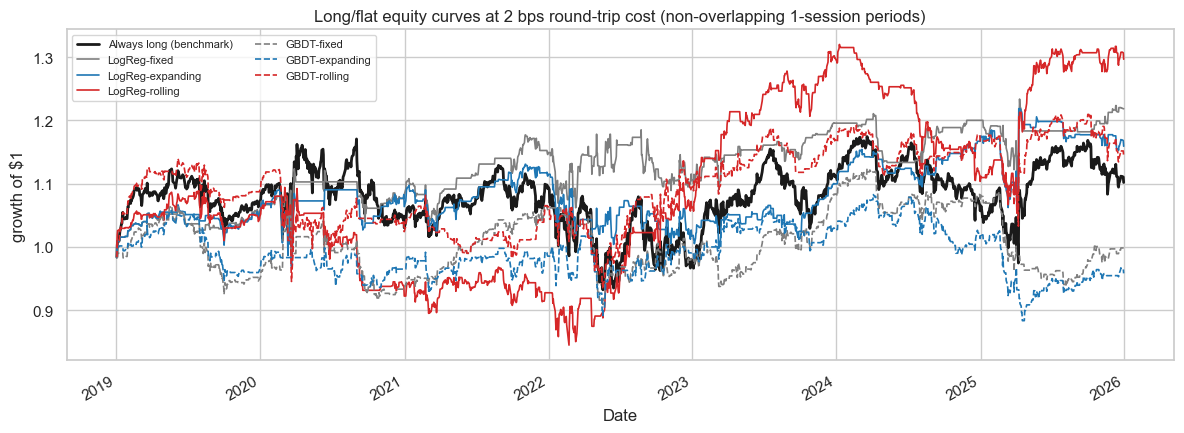

In [33]:
COST_SHOW = 2
fig, ax = plt.subplots(figsize=(12, 4.5))
curves[("Always long", COST_SHOW)].plot(ax=ax, color="k", lw=2, label="Always long (benchmark)")
for name, ls in [("LogReg", "-"), ("GBDT", "--")]:
    for s in SCHEMES:
        curves[(f"{name}-{s} [long_flat]", COST_SHOW)].plot(ax=ax, color=colors[s], ls=ls, lw=1.2, label=f"{name}-{s}")
ax.set_title(f"Long/flat equity curves at {COST_SHOW} bps round-trip cost (non-overlapping {HORIZON}-session periods)")
ax.set_ylabel("growth of $1"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); savefig("equity_curves"); plt.show()

## 16. Summary of findings

The cell below generates a plain-language summary directly from the results, so it stays correct if the data or configuration change.

In [34]:
def verdict(row, metric):
    lo, hi, d = row[(metric, "ci_low")], row[(metric, "ci_high")], row[(metric, "improvement")]
    tag = "significant improvement" if lo > 0 else "significantly worse" if hi < 0 else "not significant"
    return f"{d:+.4f} [{lo:+.4f}, {hi:+.4f}] ({tag})"

print(f"=== Horizon: {HORIZON} session(s) | test {DATES[MASK['test']].min().date()} - {DATES[MASK['test']].max().date()} "
      f"| n = {int(MASK['test'].sum())} ===\n")
print("Test metrics (all features):")
print(main[["balanced_acc", "roc_auc", "brier", "brier_skill"]].round(4).to_string(), "\n")

print("Q1. Does adaptation beat a fixed model?  (improvement with 95% block-bootstrap CI)")
for k in [k for k in comparisons if "vs fixed" in k]:
    b = boot.loc[k]
    print(f"  {k:28s} BA {verdict(b, 'balanced_acc')}\n  {'':28s} AUC {verdict(b, 'roc_auc')}\n  {'':28s} Brier {verdict(b, 'brier')}")
print("\nQ2. Do the ML models beat the majority baseline?")
for name in ["LogReg", "GBDT"]:
    for s in SCHEMES:
        b = boot.loc[f"{name}: {s} vs Majority"]
        print(f"  {name}-{s:9s} BA {verdict(b, 'balanced_acc')} | Brier {verdict(b, 'brier')}")
print("\nQ3. Do cross-market features add value? (all vs SPY-only)")
for name in ["LogReg", "GBDT"]:
    for s in SCHEMES:
        b = boot.loc[f"{name}: all vs SPY-only features ({s})"]
        print(f"  {name}-{s:9s} AUC {verdict(b, 'roc_auc')}")
best = main.drop(index="Majority").sort_values("balanced_acc", ascending=False).index[0]
print(f"\nBest test balanced accuracy: {best} = {main.loc[best, 'balanced_acc']:.4f} "
      f"(AUC {main.loc[best, 'roc_auc']:.4f}). Note: this ranking is chosen with hindsight on test data.")
print(f"Adversarial-validation AUC (train vs test features): {adv_auc:.3f}; features with PSI > 0.25: {(psi_s > 0.25).sum()}")

=== Horizon: 1 session(s) | test 2019-01-02 - 2025-12-30 | n = 1759 ===

Test metrics (all features):
                    balanced_acc  roc_auc  brier  brier_skill
model    scheme                                              
Majority fixed            0.5000   0.5000 0.2480       0.0000
         expanding        0.5000   0.4708 0.2480      -0.0000
         rolling          0.5000   0.4986 0.2486      -0.0027
LogReg   fixed            0.4996   0.4995 0.2721      -0.0975
         expanding        0.5005   0.4860 0.2630      -0.0606
         rolling          0.4983   0.5039 0.2880      -0.1615
GBDT     fixed            0.5058   0.5088 0.2620      -0.0566
         expanding        0.4988   0.4922 0.2493      -0.0056
         rolling          0.5071   0.5050 0.2502      -0.0090 

Q1. Does adaptation beat a fixed model?  (improvement with 95% block-bootstrap CI)
  LogReg: expanding vs fixed   BA +0.0009 [-0.0171, +0.0193] (not significant)
                               AUC -0.0136 [-0.0295,

### Interpretation guide & limitations

* **Effect sizes are small by design.** In liquid index markets, a balanced accuracy of 0.51–0.53 or an AUC of 0.52–0.55 can be meaningful, but only if the confidence interval excludes 0.5. Point estimates without CIs should not be interpreted.
* **Selection happened only on validation data.** Hyperparameters, retraining frequency and window length were fixed before the test period was touched. The "best model" line in the summary is descriptive (hindsight) and is not a valid out-of-sample claim.
* **Multiple comparisons.** Many pairwise tests are reported, so a few "significant" results can appear by chance. Look for consistent results across models, metrics and horizons.
* **Overlapping labels (multi-day horizon).** Consecutive multi-day labels share most of their path, so the effective sample size is much smaller than the row count. Purging and the block bootstrap (`BLOCK_LEN = max(20, 3·HORIZON)`) account for this.
* **Hyperparameters are chosen once.** Each scheme picks its hyperparameters from the top validation candidates, and they are then held constant throughout the test walk-forward. A nested re-tuning at every refit would be more adaptive but much more expensive, and its selection would be noisier.
* **Data caveats.** Yahoo's adjusted prices are recomputed retroactively, VIX is not a tradable asset, and the dataset is survivorship-free only because it uses broad ETFs.
* **The trading simulation is exploratory.** It ignores slippage, market impact, borrow fees and taxes, and its conclusions are less robust than the classification metrics.